#Modelo de mezcla gaussiana

**Fuente original:** https://www.geeksforgeeks.org/machine-learning/gaussian-mixture-model/

**Edición y Ejecución:** Carlos Francisco Montoya Urzúa

--------------

El Modelo de Mezcla Gaussiana (GMM) es una técnica probabilística de agrupamiento que modela los datos como una combinación de múltiples distribuciones gaussianas, permitiendo agrupar puntos de datos de forma más flexible.

Asigna a cada punto de datos una probabilidad de pertenecer a diferentes grupos

Puede manejar clústeres superpuestos de forma eficaz

Utiliza la media y la covarianza para definir la forma del grupo

Un Modelo de Mezcla Gaussiano asume que los datos se generan a partir de una mezcla de K distribuciones gaussianas, cada una representando un conglomerado. Cada gaussiano tiene su propio promedio
$\mu_k$, covarianza
$Σ_k$ y el peso de mezcla $\pi_k$


##1. Probabilidad posterior (responsabilidad del grupo)
Para un punto de datos dado xn, la probabilidad de que pertenezca al conglomerado k:

$$P(z_n = k \mid x_n) = \frac{\pi_k \cdot \mathcal{N}(x_n \mid \mu_k, \Sigma_k)}{\sum_{j=1}^{K} \pi_j \cdot \mathcal{N}(x_n \mid \mu_j, \Sigma_j)}$$

donde:

$z_n$ es una variable latente que indica la asignación de conglomerados

$\pi_n$ es la probabilidad de mezcla de la k-ésima gaussiana.

$\mathcal{N}(x_n \mid \mu_k, \Sigma_k)$ es la distribución gaussiana con media $\mu_k$ y covarianza $Σ_k$

##2. Probabilidad de un punto de datos
La probabilidad total de observar xnx_nxn bajo todas las gaussianas es:

$$P(x_n) = \sum_{k=1}^{K} \pi_k \cdot \mathcal{N}(x_n \mid \mu_k, \Sigma_k)$$

Esto representa lo bien que la mezcla en su conjunto explica el punto de datos.

##3. Algoritmo de Maximización de Expectativas (EM)
Los parámetros GMM se estiman usando el algoritmo EM:

Paso E (Expectación): Calcular la responsabilidad de cada clúster por cada punto de datos usando los valores actuales de los parámetros.

Paso M (Maximización): Actualización

Medios $\mu_k$

Covarianzas $Σ_k$

Mezclando coeficientes usando las responsabilidades del paso E. El proceso continúa hasta que la verosimilitud logarítmica del modelo se estabiliza.

##4. Probabilidad logarítmica del modelo de mezcla
El objetivo optimizado por EM es:

$$\mathcal{L}(\mu, \Sigma, \pi) = \prod_{n=1}^{N} \sum_{k=1}^{K} \pi_k \cdot \mathcal{N}(x_n \mid \mu_k, \Sigma_k)$$

EM aumenta esta probabilidad en cada iteración.

##Formas de agrupación en GMM
En GMM, cada clúster es una Gaussiana definida por:

Media (μ): Centro del grupo.

Covarianza (Σ): Controla la forma, orientación y dispersión del grupo.

Debido a que las matrices de covarianza permiten formas elípticas, GMM puede modelar:

Cúmulos alargados

Cúmulos inclinados

Clústeres superpuestos

Esto hace que la GMM sea más flexible que métodos como los K-Means, que asumen solo clústeres esféricos.

##Visualizar la GMM a menudo implica:
Diagramas de dispersión que muestran datos en bruto

Curvas elípticas (o curvas KDE) que muestran la forma de cada componente gaussiano

Estos ilustran cómo GMM se adapta a distribuciones de datos complejas y reales.

##Implementación del Modelo de Mezcla Gaussiana (GMM)
Importar bibliotecas requeridas.
make_blobs crea un conjunto de datos sintético sencillo para demostración.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
from sklearn.datasets import make_blobs


##Paso 1: Generar datos sintéticos

crea 500 puntos en 2D agrupados alrededor de 3 centros. cluster_std controla lo compacto o disperso que está cada grupo. Y es la etiqueta real (solo para referencia).

In [4]:
# generate 2D synthetic data with 3 centers and different spreads
X, y = make_blobs(
    n_samples=500,
    centers=3,
    random_state=42,
    cluster_std=[1.0, 1.5, 0.8]   # spread for each cluster
)


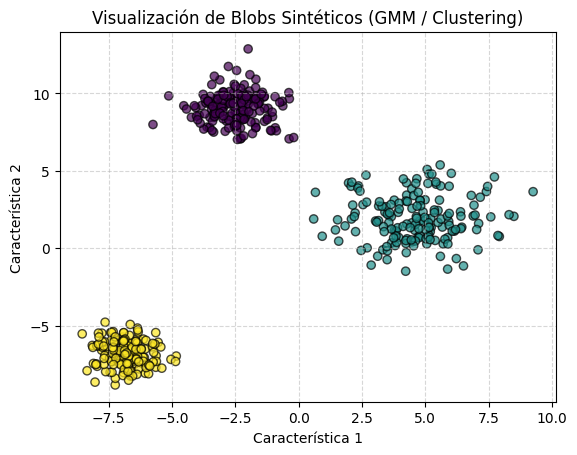

In [5]:
import matplotlib.pyplot as plt

# 2. Crear la visualización
# X[:, 0] toma la primera columna (eje X) y X[:, 1] la segunda columna (eje Y)
# c=y asigna un color automático a cada punto basado en su grupo
# cmap='viridis' define la paleta de colores
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', edgecolor='k', alpha=0.7)

# 3. Personalizar el gráfico
plt.title('Visualización de Blobs Sintéticos (GMM / Clustering)')
plt.xlabel('Característica 1')
plt.ylabel('Característica 2')
plt.grid(True, linestyle='--', alpha=0.5)

# 4. Mostrar el gráfico en Colab
plt.show()

##Paso 2: Ajustar el modelo de mezcla gaussiana

fit(X) ejecuta el algoritmo EM para aprender medias, covarianzas y pesos de mezcla.

Las etiquetas dan el índice de agrupación para cada punto (el componente con mayor probabilidad posterior).

In [6]:
gmm = GaussianMixture(
    n_components=3,        # number of Gaussian components
    covariance_type='full',
    random_state=42
)

gmm.fit(X)                # learn parameters from data
labels = gmm.predict(X)   # hard cluster assignment (highest posterior)


##Paso 3: Trazar los clústeres y los centros de componentes

Puntos coloreados por grupo asignado y marcas rojas en X que muestran los centros gaussianos aprendidos.

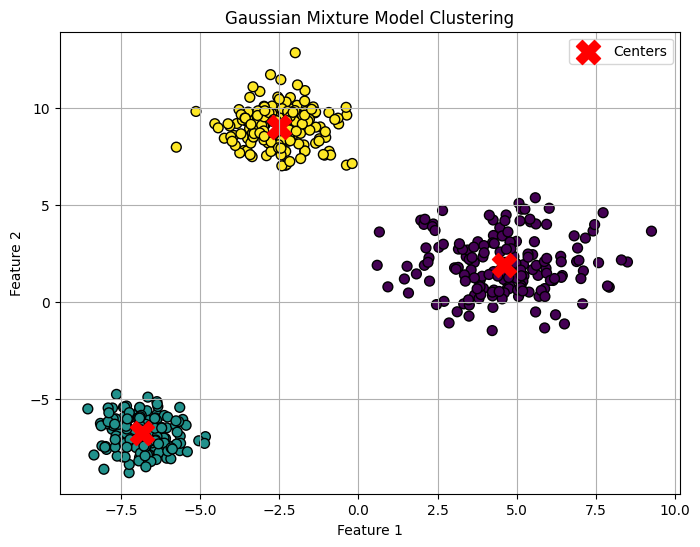

In [7]:
plt.figure(figsize=(8, 6))

# scatter points colored by hard labels
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=50, edgecolor='k')

# plot Gaussian centers
plt.scatter(
    gmm.means_[:, 0],
    gmm.means_[:, 1],
    s=300,
    c='red',
    marker='X',
    label='Centers'
)

plt.title("Gaussian Mixture Model Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(True)
plt.legend()
plt.show()


##Intento con blobs más dispersos

In [18]:
# generate 2D synthetic data with 5 centers and different spreads
X, y = make_blobs(
    n_samples=1000,
    centers=5,
    random_state=123,
    cluster_std=3   # spread for each cluster
)


In [19]:
gmm = GaussianMixture(
    n_components=5,        # number of Gaussian components
    covariance_type='full',
    random_state=42
)

gmm.fit(X)                # learn parameters from data
labels = gmm.predict(X)   # hard cluster assignment (highest posterior)


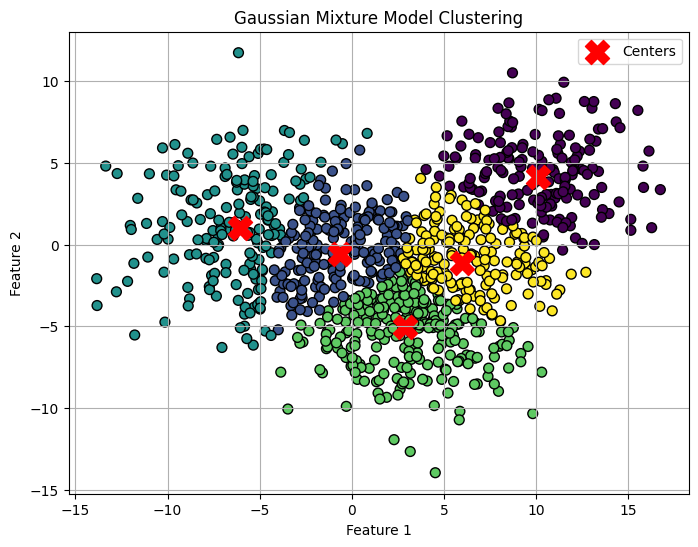

In [20]:
plt.figure(figsize=(8, 6))

# scatter points colored by hard labels
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=50, edgecolor='k')

# plot Gaussian centers
plt.scatter(
    gmm.means_[:, 0],
    gmm.means_[:, 1],
    s=300,
    c='red',
    marker='X',
    label='Centers'
)

plt.title("Gaussian Mixture Model Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(True)
plt.legend()
plt.show()


##Intento con datos de tres dimensiones

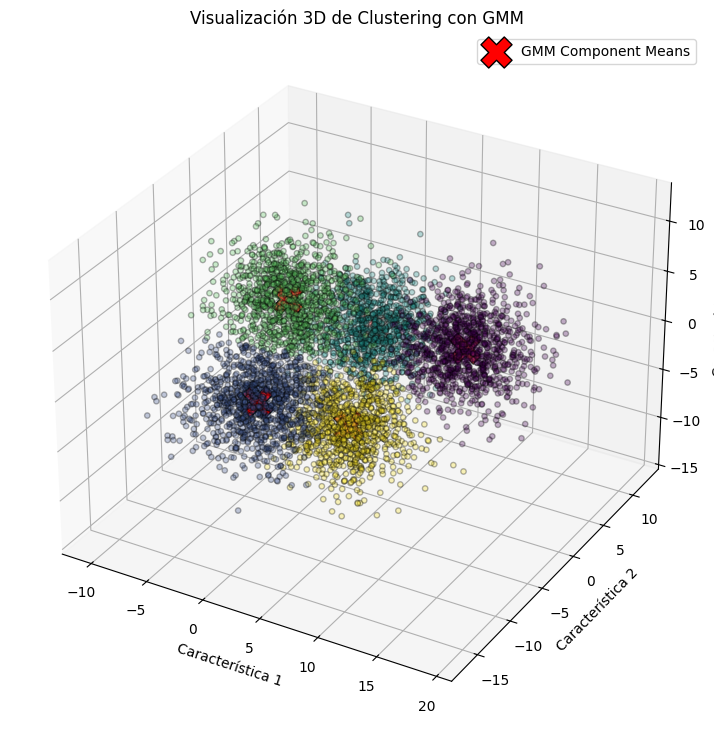

In [23]:
from mpl_toolkits.mplot3d import Axes3D

#Generar datos sintéticos en 3 dimensiones
# Usamos n_features=3 para indicar la dimensionalidad
X_3d, _ = make_blobs(
    n_samples=5000,
    centers=5,
    n_features=3,         #Cambiado a 3D
    random_state=123,
    cluster_std=2.5       # Un poco menos disperso que antes para que se aprecie el 3D
)

#Entrenar el modelo GMM en 3D
# Buscamos 5 componentes para coincidir con la generación de datos
gmm_3d = GaussianMixture(n_components=5, random_state=123)
gmm_3d.fit(X_3d)

#Obtener las etiquetas predichas para colorear
labels_3d = gmm_3d.predict(X_3d)

#Visualización 3D
fig = plt.figure(figsize=(12, 9))
# Creamos un eje con proyección '3d'
ax = fig.add_subplot(111, projection='3d')

# --- Graficar los puntos de datos ---
# X_3d[:, 0] = Eje X, X_3d[:, 1] = Eje Y, X_3d[:, 2] = Eje Z
scatter = ax.scatter(
    X_3d[:, 0],
    X_3d[:, 1],
    X_3d[:, 2],
    c=labels_3d,    # Coloreado por cluster predicho
    cmap='viridis',
    s=15,           # Puntos más pequeños para apreciar la profundidad
    edgecolor='k',
    alpha=0.3       # Alta transparencia para manejar el solapamiento en 3D
)

# --- Graficar las MEDIAS (Centros) encontradas por el GMM ---
means_3d = gmm_3d.means_
ax.scatter(
    means_3d[:, 0],
    means_3d[:, 1],
    means_3d[:, 2],
    s=500,          # Centros muy grandes
    c='red',
    marker='X',
    edgecolor='black',
    label='GMM Component Means'
)

# Personalización del gráfico 3D
ax.set_title("Visualización 3D de Clustering con GMM")
ax.set_xlabel("Característica 1")
ax.set_ylabel("Característica 2")
ax.set_zlabel("Característica 3")
ax.legend()

plt.show()

##Casos de uso
Agrupamiento: Descubre grupos o estructuras subyacentes en los datos (marketing, medicina, genética).

Detección de anomalías: Identificar casos atípicos o eventos raros (fraude, errores médicos).

Segmentación de imágenes: Separa las imágenes en regiones significativas (médica, teledetección).

Estimación de densidad: Modelar distribuciones de probabilidad complejas para modelado generativo.

##Ventajas
Formas flexibles de grupos: Modela agrupaciones elipsoidales y solapadas.

Asignaciones suaves: Asigna la pertenencia probabilística a un grupo en lugar de etiquetas duras.

Gestiona datos faltantes: Observaciones robustas a incompletas.

Parámetros interpretables: La media, la covarianza y el peso de cada Gaussiana son fáciles de interpretar.

##Limitaciones
Sensible a la inicialización: Los resultados dependen de los valores iniciales de los parámetros pueden quedarse atascados en óptimos locales.

Intensivo en computación: Lento para conjuntos de datos de alta dimensión o muy grandes.

Asume distribuciones gaussianas: No es adecuada para formas de cúmulo no gaussianas.

Requiere número de clúster: Debe especificar el número de componentes/clústeres antes de ajustar.